<a href="https://colab.research.google.com/github/Jimpang77/Feature-Data-Trade-Off/blob/main/Research_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final reproducible experiment — appended revision

**Purpose:** This section is an add-on to the existing notebook. It preserves the earlier exploratory work above so the notebook shows progression after mentor feedback. Do not use the earlier single-run or test-tuned outputs as final results. The results produced by this section are the authoritative revised experiment.

This version runs the 5-repeat experiment directly in Colab, without calling `research_revised.py`. It loads and cleans the original UCI Adult data in fresh `final_*` variables, retains all original rows, uses one stratified hold-out test set, tunes hyperparameters only on an inner validation split, and writes outputs to a new Drive folder so the prior `research_outputs` folder remains untouched.

**Run the new cells in this section from top to bottom.** You do not need to delete your old cells. Because the earlier exploratory cells contain test-set evaluations, avoid using their scores in your final paper.

In [1]:
%pip install -q ucimlrepo pandas numpy scikit-learn matplotlib

In [2]:
import json
import math
import platform
import warnings
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Any, Iterable

import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, auc, average_precision_score, f1_score,
    precision_recall_curve, roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

RANDOM_SEED = 42
print("Imports ready. Existing exploratory cells above are preserved; this section uses final_* variables.")


DATASET_NAME = "UCI Adult Income (UCI Machine Learning Repository dataset id=2)"
TARGET_COLUMN = "income"
MINIMAL_COLUMNS = ["age", "education_num", "occupation", "sex"]
ENGINEERED_COLUMNS = [
    "capital_net",
    "has_capital_gain",
    "log_capital_gain",
    "age_x_hours",
    "edu_x_hours",
    "age_sq",
]
FEATURE_SET_ORDER = ["Minimal (4)", "Raw (12)", "Engineered (18)"]
MODEL_ORDER = ["Logistic Regression", "Decision Tree", "Random Forest"]


@dataclass(frozen=True)
class ExperimentConfig:
    """Settings that define the experiment and make reruns reproducible."""

    repeats: int = 5
    base_seed: int = 42
    test_size: float = 0.20
    validation_size: float = 0.20
    requested_sample_sizes: tuple[int, ...] = (200, 400, 800, 1600, 3200, 6400, 12800)
    depth_candidates: tuple[int | None, ...] = tuple(range(3, 16)) + (None,)
    logistic_c_candidates: tuple[float, ...] = (0.01, 0.1, 1.0, 10.0, 100.0)
    n_estimators: int = 100
    n_jobs: int = -1
    max_iter: int = 3000

def normalize_column_name(value: Any) -> str:
    """Normalize Adult column labels into predictable snake_case names."""
    return (
        str(value)
        .strip()
        .lower()
        .replace("-", "_")
        .replace(".", "_")
        .replace(" ", "_")
    )


def load_adult_dataframe(csv_path: Path | None = None) -> pd.DataFrame:
    """Load the complete Adult dataset, preserving its original rows.

    By default, ucimlrepo supplies the standard 48,842-row combined dataset.
    When a CSV is supplied, it must include the target under `income`, `class`,
    or `target` (case-insensitive).
    """
    if csv_path is not None:
        if not csv_path.exists():
            raise FileNotFoundError(f"CSV not found: {csv_path}")
        frame = pd.read_csv(csv_path)
    else:
        try:
            from ucimlrepo import fetch_ucirepo
        except ImportError as exc:
            raise SystemExit(
                "The ucimlrepo package is not installed. Install dependencies with:\n"
                "  python -m pip install ucimlrepo pandas numpy scikit-learn matplotlib\n"
                "Or pass --csv PATH to a local Adult CSV."
            ) from exc

        adult = fetch_ucirepo(id=2)
        features = adult.data.features.copy()
        targets = adult.data.targets.copy()
        if not isinstance(targets, pd.DataFrame):
            targets = pd.DataFrame({TARGET_COLUMN: np.asarray(targets).reshape(-1)})
        if targets.shape[1] < 1:
            raise ValueError("UCI Adult data returned an empty target table.")
        frame = features.copy()
        frame[TARGET_COLUMN] = targets.iloc[:, 0].to_numpy()

    frame = frame.copy()
    frame.columns = [normalize_column_name(col) for col in frame.columns]
    if TARGET_COLUMN not in frame.columns:
        aliases = [name for name in ("class", "target", "income_level") if name in frame.columns]
        if aliases:
            frame = frame.rename(columns={aliases[0]: TARGET_COLUMN})
        else:
            raise ValueError(
                "The input data must contain an income target column (income, class, or target). "
                f"Found columns: {frame.columns.tolist()}"
            )
    return frame


def clean_adult_dataframe(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series, dict[str, Any]]:
    """Clean labels and text values without fitting transformations on all rows.

    Deliberately does not call drop_duplicates(): identical predictor profiles
    can belong to different census respondents, and retaining the original rows
    keeps the dataset count and sampling procedure transparent.
    """
    data = frame.copy()
    data.columns = [normalize_column_name(col) for col in data.columns]
    if TARGET_COLUMN not in data.columns:
        aliases = [name for name in ("class", "target", "income_level") if name in data.columns]
        if not aliases:
            raise ValueError("Target column not found. Expected income, class, or target.")
        data = data.rename(columns={aliases[0]: TARGET_COLUMN})

    # Normalize textual spacing and the UCI Adult '?' missing-value marker.
    for column in data.columns:
        if pd.api.types.is_object_dtype(data[column]) or pd.api.types.is_string_dtype(data[column]):
            data[column] = data[column].astype("string").str.strip()
    data = data.replace("?", np.nan)

    raw_target = data[TARGET_COLUMN].astype("string").str.strip().str.rstrip(".")
    y = raw_target.map({"<=50K": 0, ">50K": 1})
    if y.isna().any():
        unexpected = sorted(raw_target[y.isna()].dropna().astype(str).unique().tolist())
        raise ValueError(
            "Some income labels were not mapped to 0/1. Expected '<=50K' and '>50K' "
            f"(optional trailing period). Unexpected labels: {unexpected[:10]}"
        )
    y = y.astype("int8").rename(TARGET_COLUMN).reset_index(drop=True)

    feature_data = data.drop(columns=[TARGET_COLUMN]).copy()
    # Numeric predictors must remain numeric; coercion leaves any invalid entry
    # as NaN for the training-fitted median imputer in the sklearn pipeline.
    known_numeric = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
    for column in known_numeric:
        if column in feature_data.columns:
            feature_data[column] = pd.to_numeric(feature_data[column], errors="coerce")

    # The study defines Raw as the 12 original predictors after these two drops.
    removed = {}
    if "education" in feature_data.columns:
        feature_data = feature_data.drop(columns=["education"])
        removed["education"] = "Redundant textual counterpart of education_num"
    if "fnlwgt" in feature_data.columns:
        feature_data = feature_data.drop(columns=["fnlwgt"])
        removed["fnlwgt"] = "Census sampling weight excluded from the predictor set"

    for column in feature_data.columns:
        if pd.api.types.is_object_dtype(feature_data[column]) or pd.api.types.is_string_dtype(feature_data[column]):
            feature_data[column] = feature_data[column].fillna("Unknown").astype(str)

    # The adult dataset should have 12 raw predictors after the two documented drops.
    if len(feature_data.columns) != 12:
        raise ValueError(
            "Expected exactly 12 raw predictors after dropping education and fnlwgt, "
            f"but found {len(feature_data.columns)}: {feature_data.columns.tolist()}. "
            "Check the input file/schema rather than silently changing feature-set labels."
        )
    missing_minimal = sorted(set(MINIMAL_COLUMNS) - set(feature_data.columns))
    required_engineering = {"capital_gain", "capital_loss", "age", "hours_per_week", "education_num"}
    missing_engineering = sorted(required_engineering - set(feature_data.columns))
    if missing_minimal or missing_engineering:
        raise ValueError(
            f"Required Adult predictors are missing. Minimal missing={missing_minimal}; "
            f"feature-engineering inputs missing={missing_engineering}."
        )

    audit = {
        "original_row_count": int(len(data)),
        "rows_removed": 0,
        "duplicate_rows_removed": 0,
        "removed_columns_and_reasons": removed,
        "raw_predictor_columns": feature_data.columns.tolist(),
        "raw_predictor_count": int(len(feature_data.columns)),
        "engineered_columns": ENGINEERED_COLUMNS,
        "target_counts": {str(k): int(v) for k, v in y.value_counts().sort_index().items()},
    }
    return feature_data.reset_index(drop=True), y, audit

Imports ready. Existing exploratory cells above are preserved; this section uses final_* variables.


In [3]:
final_frame = load_adult_dataframe()
final_raw_features, final_y, final_audit = clean_adult_dataframe(final_frame)

print(f"Rows retained: {len(final_y):,}")
print(f"Raw predictor count: {len(final_raw_features.columns)}")
print("Removed columns:", final_audit["removed_columns_and_reasons"])
print("Target counts:", final_audit["target_counts"])
print("\nRaw predictor columns:")
print(final_raw_features.columns.tolist())

assert len(final_y) == 48_842, (
    f"Expected 48,842 original Adult rows, found {len(final_y):,}. "
    "Check the source dataset version before interpreting the results."
)
assert len(final_raw_features.columns) == 12
assert set(final_y.unique()) == {0, 1}
display(final_raw_features.head())

Rows retained: 48,842
Raw predictor count: 12
Removed columns: {'education': 'Redundant textual counterpart of education_num', 'fnlwgt': 'Census sampling weight excluded from the predictor set'}
Target counts: {'0': 37155, '1': 11687}

Raw predictor columns:
['age', 'workclass', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country']


,age,workclass,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country
0,39,State-gov,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba


In [4]:
# Define feature engineering, training-only preprocessing, validation tuning,
# and the reproducible sampling procedure used by the final experiment.

def add_engineered_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Add exactly six row-wise features; no statistics are learned here."""
    d = frame.copy()
    for column in ["capital_gain", "capital_loss", "age", "hours_per_week", "education_num"]:
        d[column] = pd.to_numeric(d[column], errors="coerce")
    d["capital_net"] = d["capital_gain"] - d["capital_loss"]
    d["has_capital_gain"] = (d["capital_gain"] > 0).astype("int8")
    # Capital gain is nonnegative in Adult; clip guards against malformed input.
    d["log_capital_gain"] = np.log1p(d["capital_gain"].clip(lower=0))
    d["age_x_hours"] = d["age"] * d["hours_per_week"]
    d["edu_x_hours"] = d["education_num"] * d["hours_per_week"]
    d["age_sq"] = d["age"] ** 2
    return d


def build_feature_frames(raw_features: pd.DataFrame) -> dict[str, pd.DataFrame]:
    """Create the three named feature representations, in a fixed order."""
    raw = raw_features.copy()
    engineered = add_engineered_features(raw)
    frames = {
        "Minimal (4)": raw[MINIMAL_COLUMNS].copy(),
        "Raw (12)": raw.copy(),
        "Engineered (18)": engineered[raw.columns.tolist() + ENGINEERED_COLUMNS].copy(),
    }
    return frames


def make_preprocessor(frame: pd.DataFrame) -> ColumnTransformer:
    """Build preprocessing that is fitted only on the supplied training fold."""
    numeric_columns = frame.select_dtypes(include=[np.number]).columns.tolist()
    categorical_columns = [c for c in frame.columns if c not in numeric_columns]

    transformers: list[tuple[str, Pipeline, list[str]]] = []
    if numeric_columns:
        numeric_pipeline = Pipeline(
            steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]
        )
        transformers.append(("numeric", numeric_pipeline, numeric_columns))
    if categorical_columns:
        categorical_pipeline = Pipeline(
            steps=[
                ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]
        )
        transformers.append(("categorical", categorical_pipeline, categorical_columns))

    if not transformers:
        raise ValueError("No input columns were available for preprocessing.")
    return ColumnTransformer(transformers=transformers, remainder="drop")


def make_classifier(
    model_name: str,
    params: dict[str, Any],
    random_state: int,
    config: ExperimentConfig,
) -> Any:
    """Create a classifier with every material hyperparameter explicit."""
    if model_name == "Logistic Regression":
        return LogisticRegression(
            C=float(params["C"]),
            solver="lbfgs",
            max_iter=config.max_iter,
            random_state=int(random_state),
        )
    if model_name == "Decision Tree":
        return DecisionTreeClassifier(
            max_depth=params["max_depth"],
            min_samples_leaf=1,
            criterion="gini",
            random_state=int(random_state),
        )
    if model_name == "Random Forest":
        return RandomForestClassifier(
            n_estimators=int(config.n_estimators),
            max_depth=params["max_depth"],
            min_samples_leaf=1,
            max_features="sqrt",
            bootstrap=True,
            criterion="gini",
            n_jobs=int(config.n_jobs),
            random_state=int(random_state),
        )
    raise ValueError(f"Unknown model name: {model_name}")


def candidate_parameters(model_name: str, config: ExperimentConfig) -> list[dict[str, Any]]:
    if model_name == "Logistic Regression":
        return [{"C": value} for value in config.logistic_c_candidates]
    return [{"max_depth": value} for value in config.depth_candidates]


def parameter_label(model_name: str, params: dict[str, Any]) -> str:
    if model_name == "Logistic Regression":
        return f"C={params['C']:g}"
    depth = params["max_depth"]
    return "Unrestricted" if depth is None else f"Depth {depth}"


def parameter_complexity_key(model_name: str, params: dict[str, Any]) -> tuple[float, ...]:
    """Prefer simpler settings when validation scores are numerically tied."""
    if model_name == "Logistic Regression":
        # Smaller C means stronger regularization.
        return (float(params["C"]),)
    depth = params["max_depth"]
    return (math.inf if depth is None else float(depth),)


def tune_on_validation(
    model_name: str,
    X_fit: pd.DataFrame,
    y_fit: pd.Series,
    X_validation: pd.DataFrame,
    y_validation: pd.Series,
    random_state: int,
    config: ExperimentConfig,
) -> tuple[dict[str, Any], list[dict[str, Any]]]:
    """Select hyperparameters using validation ROC-AUC, never test-set scores.

    The preprocessor is fit on X_fit only. Its transformed matrices are reused
    across candidates, avoiding repeated one-hot encoding/scaling work during
    the depth search.
    """
    preprocessor = make_preprocessor(X_fit)
    X_fit_processed = preprocessor.fit_transform(X_fit)
    X_validation_processed = preprocessor.transform(X_validation)

    candidate_rows: list[dict[str, Any]] = []
    scored_candidates: list[tuple[float, tuple[float, ...], dict[str, Any]]] = []
    for params in candidate_parameters(model_name, config):
        classifier = make_classifier(model_name, params, random_state, config)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            classifier.fit(X_fit_processed, y_fit)
        probabilities = classifier.predict_proba(X_validation_processed)[:, 1]
        score = float(roc_auc_score(y_validation, probabilities))
        candidate_rows.append(
            {
                "model": model_name,
                "parameter_label": parameter_label(model_name, params),
                "params_json": json.dumps(params, sort_keys=True),
                "validation_roc_auc": score,
                "n_validation_rows": int(len(y_validation)),
                "convergence_warning": any("converg" in str(w.message).lower() for w in caught),
            }
        )
        scored_candidates.append((score, parameter_complexity_key(model_name, params), params))

    if not scored_candidates:
        raise RuntimeError(f"No hyperparameter candidates were evaluated for {model_name}.")
    best_score = max(item[0] for item in scored_candidates)
    tied = [item for item in scored_candidates if np.isclose(item[0], best_score, rtol=0, atol=1e-12)]
    _, _, best_params = min(tied, key=lambda item: item[1])
    return dict(best_params), candidate_rows


def stratified_nested_order(y: pd.Series, seed: int) -> np.ndarray:
    """Create a reproducible, approximately stratified ordering without replacement.

    Taking a prefix of this order gives nested subsets for increasing sample
    sizes. Rows are sorted back to their original training order after selection
    before fitting, so a full-size sample has stable row ordering.
    """
    y_array = np.asarray(y)
    rng = np.random.default_rng(seed)
    events: list[tuple[float, float, int]] = []
    for label in np.unique(y_array):
        positions = np.flatnonzero(y_array == label)
        rng.shuffle(positions)
        count = len(positions)
        if count == 0:
            continue
        jitter = rng.random(count)
        for rank, position in enumerate(positions):
            key = (rank + jitter[rank]) / count
            events.append((float(key), float(rng.random()), int(position)))
    events.sort(key=lambda item: (item[0], item[1]))
    order = np.asarray([item[2] for item in events], dtype=int)
    if len(order) != len(y_array) or len(np.unique(order)) != len(y_array):
        raise RuntimeError("Nested sampler did not produce a permutation of the training rows.")
    return order


def choose_sample_sizes(train_size: int, requested: Iterable[int]) -> list[int]:
    valid = sorted({int(n) for n in requested if 2 <= int(n) < train_size})
    return valid + [int(train_size)]


def evaluate_metrics(y_true: pd.Series, probabilities: np.ndarray) -> dict[str, float]:
    predictions = (probabilities >= 0.5).astype(int)
    precision, recall, _ = precision_recall_curve(y_true, probabilities)
    return {
        "test_roc_auc": float(roc_auc_score(y_true, probabilities)),
        "test_pr_auc": float(auc(recall, precision)),
        "test_average_precision": float(average_precision_score(y_true, probabilities)),
        "test_accuracy": float(accuracy_score(y_true, predictions)),
        "test_f1": float(f1_score(y_true, predictions, zero_division=0)),
    }


def transformed_feature_count(pipeline: Pipeline, example_frame: pd.DataFrame) -> int:
    fitted_preprocessor = pipeline.named_steps["preprocessor"]
    try:
        return int(len(fitted_preprocessor.get_feature_names_out()))
    except (AttributeError, TypeError, ValueError):
        return int(fitted_preprocessor.transform(example_frame.iloc[:1]).shape[1])

In [5]:
# Define the end-to-end experiment runner. Each test score is computed only
# after the hyperparameters have been chosen using the inner validation split.

def run_experiment(
    raw_features: pd.DataFrame,
    y: pd.Series,
    audit: dict[str, Any],
    config: ExperimentConfig,
    output_dir: Path,
) -> dict[str, pd.DataFrame]:
    """Run all conditions and write auditable results plus figures."""
    output_dir.mkdir(parents=True, exist_ok=True)
    if config.repeats < 2:
        warnings.warn(
            "Fewer than two repeats cannot provide a useful across-run standard deviation.",
            RuntimeWarning,
        )
    if len(np.unique(y)) != 2:
        raise ValueError("The target must contain both income classes.")

    feature_frames = build_feature_frames(raw_features)
    row_positions = np.arange(len(y))
    train_positions, test_positions = train_test_split(
        row_positions,
        test_size=config.test_size,
        random_state=config.base_seed,
        stratify=np.asarray(y),
    )
    train_y = y.iloc[train_positions].reset_index(drop=True)
    test_y = y.iloc[test_positions].reset_index(drop=True)
    train_frames = {
        feature_set: frame.iloc[train_positions].reset_index(drop=True)
        for feature_set, frame in feature_frames.items()
    }
    test_frames = {
        feature_set: frame.iloc[test_positions].reset_index(drop=True)
        for feature_set, frame in feature_frames.items()
    }
    sample_sizes = choose_sample_sizes(len(train_y), config.requested_sample_sizes)
    if sample_sizes[0] < 10:
        raise ValueError("The smallest requested sample size must be at least 10 rows.")

    run_rows: list[dict[str, Any]] = []
    candidate_rows_all: list[dict[str, Any]] = []
    expected_conditions = config.repeats * len(sample_sizes) * len(feature_frames) * len(MODEL_ORDER)
    completed_conditions = 0

    print(f"Dataset rows retained: {len(y):,}")
    print(f"Stratified training rows: {len(train_y):,}; untouched hold-out test rows: {len(test_y):,}")
    print(f"Sample sizes: {sample_sizes}")
    print(f"Repeats: {config.repeats}; Random Forest trees per fit: {config.n_estimators}")
    print("Hyperparameters are selected only on the inner validation split; test scores are not used for tuning.")

    for repeat_index in range(config.repeats):
        repeat_seed = config.base_seed + 1009 * (repeat_index + 1)
        nested_order = stratified_nested_order(train_y, repeat_seed)

        for sample_size in sample_sizes:
            selected_positions = np.sort(nested_order[:sample_size])
            y_sample = train_y.iloc[selected_positions].reset_index(drop=True)
            # Same row subset and same inner split for all three models and feature sets.
            fit_local, validation_local = train_test_split(
                np.arange(sample_size),
                test_size=config.validation_size,
                random_state=config.base_seed + repeat_index * 100_000 + sample_size,
                stratify=np.asarray(y_sample),
            )
            y_fit = y_sample.iloc[fit_local].reset_index(drop=True)
            y_validation = y_sample.iloc[validation_local].reset_index(drop=True)
            model_seed = int(config.base_seed + repeat_index * 10_000 + sample_size)

            for feature_set in FEATURE_SET_ORDER:
                full_sample_X = train_frames[feature_set].iloc[selected_positions].reset_index(drop=True)
                X_fit = full_sample_X.iloc[fit_local].reset_index(drop=True)
                X_validation = full_sample_X.iloc[validation_local].reset_index(drop=True)
                X_test = test_frames[feature_set]
                n_original_features = int(full_sample_X.shape[1])

                for model_name in MODEL_ORDER:
                    best_params, candidate_rows = tune_on_validation(
                        model_name=model_name,
                        X_fit=X_fit,
                        y_fit=y_fit,
                        X_validation=X_validation,
                        y_validation=y_validation,
                        random_state=model_seed,
                        config=config,
                    )
                    for row in candidate_rows:
                        row.update(
                            {
                                "repeat": repeat_index + 1,
                                "repeat_seed": repeat_seed,
                                "sample_size": int(sample_size),
                                "feature_set": feature_set,
                            }
                        )
                        if model_name == "Logistic Regression":
                            row["C"] = json.loads(row["params_json"])["C"]
                            row["max_depth"] = np.nan
                            row["depth_position"] = np.nan
                            row["max_depth_label"] = "Not applicable"
                        else:
                            depth = json.loads(row["params_json"])["max_depth"]
                            row["C"] = np.nan
                            row["max_depth"] = "Unrestricted" if depth is None else int(depth)
                            row["depth_position"] = 16 if depth is None else int(depth)
                            row["max_depth_label"] = "Unrestricted" if depth is None else str(int(depth))
                    candidate_rows_all.extend(candidate_rows)

                    # Refit the chosen configuration on the entire sampled training subset,
                    # including its inner-validation rows. The test set remains untouched.
                    final_pipeline = Pipeline(
                        steps=[
                            ("preprocessor", make_preprocessor(full_sample_X)),
                            ("classifier", make_classifier(model_name, best_params, model_seed, config)),
                        ]
                    )
                    with warnings.catch_warnings(record=True) as caught_final:
                        warnings.simplefilter("always")
                        final_pipeline.fit(full_sample_X, y_sample)
                    test_probabilities = final_pipeline.predict_proba(X_test)[:, 1]
                    metrics = evaluate_metrics(test_y, test_probabilities)
                    n_encoded_features = transformed_feature_count(final_pipeline, full_sample_X)
                    run_rows.append(
                        {
                            "repeat": repeat_index + 1,
                            "repeat_seed": repeat_seed,
                            "sample_size": int(sample_size),
                            "model": model_name,
                            "feature_set": feature_set,
                            "n_original_features": n_original_features,
                            "n_encoded_features": n_encoded_features,
                            "best_params_json": json.dumps(best_params, sort_keys=True),
                            "selected_validation_roc_auc": float(
                                max(row["validation_roc_auc"] for row in candidate_rows)
                            ),
                            "final_fit_convergence_warning": any(
                                "converg" in str(w.message).lower() for w in caught_final
                            ),
                            **metrics,
                        }
                    )
                    completed_conditions += 1
                    print(
                        f"[{completed_conditions:>3}/{expected_conditions}] "
                        f"repeat={repeat_index + 1}, n={sample_size:,}, {model_name}, {feature_set}: "
                        f"test ROC-AUC={metrics['test_roc_auc']:.4f}; params={best_params}"
                    )

    run_results = pd.DataFrame(run_rows)
    candidate_scores = pd.DataFrame(candidate_rows_all)
    metric_columns = ["test_roc_auc", "test_pr_auc", "test_average_precision", "test_accuracy", "test_f1"]
    summary = (
        run_results.groupby(["model", "feature_set", "sample_size"])[metric_columns]
        .agg(["mean", "std"])
        .reset_index()
    )
    # Flatten the multi-index created by pandas groupby/agg.
    summary.columns = [
        "_".join(str(part) for part in column if part != "").strip("_")
        if isinstance(column, tuple)
        else str(column)
        for column in summary.columns
    ]
    # Normalize the names of group columns across pandas versions.
    rename_groups = {"model_": "model", "feature_set_": "feature_set", "sample_size_": "sample_size"}
    summary = summary.rename(columns=rename_groups)

    full_sample_size = int(len(train_y))
    full_summary = summary.loc[summary["sample_size"] == full_sample_size].copy()
    full_summary.to_csv(output_dir / "full_training_size_feature_set_comparison.csv", index=False)

    # Validation depth scores are the same candidate evaluations used for model selection.
    depth_scores = candidate_scores.loc[candidate_scores["model"].isin(["Decision Tree", "Random Forest"])].copy()
    depth_scores.to_csv(output_dir / "validation_hyperparameter_scores.csv", index=False)
    depth_summary = (
        depth_scores.groupby(
            ["model", "feature_set", "sample_size", "max_depth", "depth_position", "max_depth_label"],
            dropna=False,
        )["validation_roc_auc"]
        .agg(["mean", "std"])
        .reset_index()
    )
    depth_summary.columns = [
        "_".join(str(part) for part in column if part != "").strip("_")
        if isinstance(column, tuple)
        else str(column)
        for column in depth_summary.columns
    ]
    depth_summary = depth_summary.rename(
        columns={
            "model_": "model",
            "feature_set_": "feature_set",
            "sample_size_": "sample_size",
            "max_depth_": "max_depth",
            "depth_position_": "depth_position",
            "max_depth_label_": "max_depth_label",
            "mean": "validation_roc_auc_mean",
            "std": "validation_roc_auc_std",
        }
    )

    sample_equivalents_by_repeat, sample_equivalents_summary = calculate_sample_size_equivalents(run_results)

    run_results.to_csv(output_dir / "run_level_results.csv", index=False)
    summary.to_csv(output_dir / "learning_curve_summary.csv", index=False)
    candidate_scores.to_csv(output_dir / "all_validation_candidate_scores.csv", index=False)
    depth_summary.to_csv(output_dir / "validation_depth_summary.csv", index=False)
    sample_equivalents_by_repeat.to_csv(output_dir / "sample_size_equivalents_by_repeat.csv", index=False)
    sample_equivalents_summary.to_csv(output_dir / "sample_size_equivalents_summary.csv", index=False)

    column_audit = pd.DataFrame(
        [
            {"column": column, "action": "removed before modeling", "reason": reason}
            for column, reason in audit["removed_columns_and_reasons"].items()
        ]
        + [
            {"column": column, "action": "retained as raw predictor", "reason": "Part of Raw (12) feature set"}
            for column in audit["raw_predictor_columns"]
        ]
        + [
            {"column": column, "action": "engineered predictor", "reason": "Row-wise deterministic feature transformation"}
            for column in ENGINEERED_COLUMNS
        ]
    )
    column_audit.to_csv(output_dir / "column_and_feature_audit.csv", index=False)

    plot_learning_curves(summary, sample_sizes, output_dir)
    plot_depth_curves(depth_summary, sample_sizes, config, output_dir)

    metadata = {
        "dataset": DATASET_NAME,
        "dataset_rows_after_cleaning": int(len(y)),
        "training_rows": int(len(train_y)),
        "holdout_test_rows": int(len(test_y)),
        "holdout_split": {
            "test_fraction": config.test_size,
            "stratified": True,
            "random_state": config.base_seed,
        },
        "repeats": config.repeats,
        "repeat_seeds": [int(config.base_seed + 1009 * (i + 1)) for i in range(config.repeats)],
        "sampling": (
            "For each repeat, one randomized approximately stratified ordering is built; prefixes "
            "produce nested subsets without replacement. The same selected rows are used across all models and feature sets."
        ),
        "hyperparameter_selection": (
            "For each repeat/sample-size/feature-set/model condition, candidate settings are scored on an inner "
            "stratified validation split from the sampled training rows. The selected setting is refit on all rows "
            "in that sampled subset. Hold-out test labels/scores are not used for tuning."
        ),
        "metrics": ["ROC-AUC", "PR-AUC (trapezoidal area under the precision-recall curve)", "Average Precision", "Accuracy", "F1"],
        "metric_uncertainty_note": (
            "Summary SD/error bars describe variation across repeat-specific nested training subsets, validation splits, "
            "and model random seeds on one fixed hold-out test set; they are not confidence intervals over new test samples."
        ),
        "sample_sizes_evaluated": sample_sizes,
        "feature_sets": {
            "Minimal (4)": {"columns": MINIMAL_COLUMNS, "original_predictor_count": 4},
            "Raw (12)": {"columns": audit["raw_predictor_columns"], "original_predictor_count": 12},
            "Engineered (18)": {
                "original_predictor_count": 18,
                "new_columns": ENGINEERED_COLUMNS,
            },
        },
        "hyperparameters": {
            "Logistic Regression": {
                "C_candidates": list(config.logistic_c_candidates),
                "solver": "lbfgs",
                "max_iter": config.max_iter,
            },
            "Decision Tree": {
                "max_depth_candidates": ["Unrestricted" if d is None else d for d in config.depth_candidates],
                "criterion": "gini",
                "min_samples_leaf": 1,
                "random_state": "repeat/sample-size derived seed",
            },
            "Random Forest": {
                "n_estimators": config.n_estimators,
                "max_depth_candidates": ["Unrestricted" if d is None else d for d in config.depth_candidates],
                "criterion": "gini",
                "min_samples_leaf": 1,
                "max_features": "sqrt",
                "bootstrap": True,
                "n_jobs": config.n_jobs,
                "random_state": "repeat/sample-size derived seed",
            },
        },
        "audit": audit,
        "software": {
            "python": platform.python_version(),
            "pandas": pd.__version__,
            "numpy": np.__version__,
            "scikit_learn": sklearn.__version__,
            "matplotlib": matplotlib.__version__,
        },
        "config": asdict(config),
    }
    # Convert Path/tuple/numpy scalar types so metadata is valid portable JSON.
    (output_dir / "experiment_metadata.json").write_text(
        json.dumps(metadata, indent=2, default=_json_default), encoding="utf-8"
    )

    print("\nExperiment complete. Files written to:", output_dir.resolve())
    print("Primary files:")
    for filename in [
        "full_training_size_feature_set_comparison.csv",
        "learning_curve_summary.csv",
        "validation_depth_summary.csv",
        "sample_size_equivalents_summary.csv",
        "experiment_metadata.json",
    ]:
        print(f"  - {filename}")

    return {
        "run_results": run_results,
        "summary": summary,
        "candidate_scores": candidate_scores,
        "depth_summary": depth_summary,
        "sample_equivalents_by_repeat": sample_equivalents_by_repeat,
        "sample_equivalents_summary": sample_equivalents_summary,
    }

In [6]:
# Output helpers: estimate sample-size equivalents and save learning/depth plots.

def _json_default(value: Any) -> Any:
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, tuple):
        return list(value)
    raise TypeError(f"Object of type {type(value).__name__} is not JSON serializable")


def calculate_sample_size_equivalents(
    run_results: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Estimate raw-feature sample sizes matching engineered-feature AUC.

    For each model/repeat/engineered sample size, find the smallest tested Raw
    sample size whose hold-out test ROC-AUC equals or exceeds the engineered
    score. Cases not matched by any tested Raw size are explicitly marked as
    not reached rather than extrapolated.
    """
    records: list[dict[str, Any]] = []
    grouped = {
        (model, int(repeat)): part
        for (model, repeat), part in run_results.groupby(["model", "repeat"])
    }
    for (model, repeat), part in grouped.items():
        raw = part.loc[part["feature_set"] == "Raw (12)", ["sample_size", "test_roc_auc"]].sort_values("sample_size")
        engineered = part.loc[
            part["feature_set"] == "Engineered (18)", ["sample_size", "test_roc_auc"]
        ].sort_values("sample_size")
        for row in engineered.itertuples(index=False):
            matches = raw.loc[raw["test_roc_auc"] >= row.test_roc_auc]
            reached = not matches.empty
            raw_equivalent = int(matches.iloc[0]["sample_size"]) if reached else np.nan
            records.append(
                {
                    "model": model,
                    "repeat": int(repeat),
                    "engineered_sample_size": int(row.sample_size),
                    "engineered_test_roc_auc": float(row.test_roc_auc),
                    "raw_equivalent_sample_size": raw_equivalent,
                    "raw_to_engineered_size_ratio": (
                        float(raw_equivalent / row.sample_size) if reached else np.nan
                    ),
                    "equivalent_reached_within_tested_sizes": bool(reached),
                }
            )
    by_repeat = pd.DataFrame(records)
    if by_repeat.empty:
        return by_repeat, by_repeat.copy()

    summary_rows: list[dict[str, Any]] = []
    for (model, engineered_size), part in by_repeat.groupby(["model", "engineered_sample_size"]):
        valid_sizes = part["raw_equivalent_sample_size"].dropna().astype(float)
        valid_ratios = part["raw_to_engineered_size_ratio"].dropna().astype(float)
        summary_rows.append(
            {
                "model": model,
                "engineered_sample_size": int(engineered_size),
                "repeats": int(len(part)),
                "repeats_with_observed_raw_equivalent": int(part["equivalent_reached_within_tested_sizes"].sum()),
                "raw_equivalent_size_median": float(valid_sizes.median()) if len(valid_sizes) else np.nan,
                "raw_equivalent_size_q25": float(valid_sizes.quantile(0.25)) if len(valid_sizes) else np.nan,
                "raw_equivalent_size_q75": float(valid_sizes.quantile(0.75)) if len(valid_sizes) else np.nan,
                "size_ratio_median": float(valid_ratios.median()) if len(valid_ratios) else np.nan,
                "size_ratio_q25": float(valid_ratios.quantile(0.25)) if len(valid_ratios) else np.nan,
                "size_ratio_q75": float(valid_ratios.quantile(0.75)) if len(valid_ratios) else np.nan,
            }
        )
    return by_repeat, pd.DataFrame(summary_rows)


def plot_learning_curves(
    summary: pd.DataFrame,
    sample_sizes: list[int],
    output_dir: Path,
) -> None:
    """Create one learning-curve figure per model with mean ± SD error bars."""
    for model_name in MODEL_ORDER:
        fig, ax = plt.subplots(figsize=(8.5, 5.5))
        model_rows = summary.loc[summary["model"] == model_name]
        for feature_set in FEATURE_SET_ORDER:
            subset = model_rows.loc[model_rows["feature_set"] == feature_set].sort_values("sample_size")
            if subset.empty:
                continue
            y_mean = subset["test_roc_auc_mean"].to_numpy(dtype=float)
            y_sd = subset["test_roc_auc_std"].fillna(0).to_numpy(dtype=float)
            ax.errorbar(
                subset["sample_size"].to_numpy(dtype=int),
                y_mean,
                yerr=y_sd,
                marker="o",
                linewidth=1.8,
                capsize=3,
                label=feature_set,
            )
        ax.set_title(f"{model_name}: Learning Curve")
        ax.set_xlabel("Training examples used to fit the final model")
        ax.set_ylabel("Hold-out test ROC-AUC (mean ± SD across repeats)")
        ax.set_xscale("log", base=2)
        ax.set_xticks(sample_sizes)
        ax.set_xticklabels([f"{n:,}" for n in sample_sizes], rotation=35, ha="right")
        ax.set_ylim(0.50, 1.00)
        ax.grid(True, alpha=0.25)
        ax.legend(title="Feature set")
        fig.tight_layout()
        filename = model_name.lower().replace(" ", "_") + "_learning_curve.png"
        fig.savefig(output_dir / filename, dpi=200, bbox_inches="tight")
        plt.close(fig)


def plot_depth_curves(
    depth_summary: pd.DataFrame,
    sample_sizes: list[int],
    config: ExperimentConfig,
    output_dir: Path,
) -> None:
    """Plot validation-only depth sensitivity, with common y scales per model."""
    if depth_summary.empty:
        return
    # None (unrestricted) is shown as a final categorical position after depth 15.
    for model_name in ["Decision Tree", "Random Forest"]:
        model_rows = depth_summary.loc[depth_summary["model"] == model_name]
        if model_rows.empty:
            continue
        fig, axes = plt.subplots(2, 4, figsize=(18, 9), sharex=True, sharey=True)
        axes_flat = axes.flatten()
        for axis, sample_size in zip(axes_flat, sample_sizes):
            n_rows = model_rows.loc[model_rows["sample_size"] == sample_size]
            for feature_set in FEATURE_SET_ORDER:
                subset = n_rows.loc[n_rows["feature_set"] == feature_set].sort_values("depth_position")
                if subset.empty:
                    continue
                axis.errorbar(
                    subset["depth_position"].to_numpy(dtype=float),
                    subset["validation_roc_auc_mean"].to_numpy(dtype=float),
                    yerr=subset["validation_roc_auc_std"].fillna(0).to_numpy(dtype=float),
                    marker="o",
                    markersize=3,
                    linewidth=1.2,
                    capsize=2,
                    label=feature_set,
                )
            axis.set_title(f"n = {sample_size:,}")
            axis.set_ylim(0.50, 1.00)
            axis.grid(True, alpha=0.22)
            axis.set_xticks([3, 5, 7, 9, 11, 13, 15, 16])
            axis.set_xticklabels(["3", "5", "7", "9", "11", "13", "15", "None"])
        for axis in axes_flat[len(sample_sizes):]:
            axis.set_visible(False)
        fig.suptitle(f"{model_name}: Validation ROC-AUC by Maximum Tree Depth (mean ± SD)", y=0.985)
        fig.supxlabel("max_depth (None = unrestricted)", y=0.075)
        fig.supylabel("Inner-validation ROC-AUC")
        handles, labels = axes_flat[0].get_legend_handles_labels()
        if handles:
            fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0.015))
        fig.tight_layout(rect=(0, 0.12, 1, 0.94))
        filename = model_name.lower().replace(" ", "_") + "_depth_validation.png"
        fig.savefig(output_dir / filename, dpi=200, bbox_inches="tight")
        plt.close(fig)

In [8]:
# Run the complete five-repeat experiment.
# This folder is intentionally separate from the earlier research_outputs folder.

from google.colab import drive
drive.mount('/content/drive')

final_config = ExperimentConfig(repeats=5)
final_output_dir = Path('/content/drive/MyDrive/research_outputs_colab_final')

final_results = run_experiment(
    raw_features=final_raw_features,
    y=final_y,
    audit=final_audit,
    config=final_config,
    output_dir=final_output_dir,
)

print("\nSaved final experiment outputs to:", final_output_dir)

Mounted at /content/drive
Dataset rows retained: 48,842
Stratified training rows: 39,073; untouched hold-out test rows: 9,769
Sample sizes: [200, 400, 800, 1600, 3200, 6400, 12800, 39073]
Repeats: 5; Random Forest trees per fit: 100
Hyperparameters are selected only on the inner validation split; test scores are not used for tuning.
[  1/360] repeat=1, n=200, Logistic Regression, Minimal (4): test ROC-AUC=0.8044; params={'C': 1.0}
[  2/360] repeat=1, n=200, Decision Tree, Minimal (4): test ROC-AUC=0.7441; params={'max_depth': 3}
[  3/360] repeat=1, n=200, Random Forest, Minimal (4): test ROC-AUC=0.8061; params={'max_depth': 3}
[  4/360] repeat=1, n=200, Logistic Regression, Raw (12): test ROC-AUC=0.8789; params={'C': 10.0}
[  5/360] repeat=1, n=200, Decision Tree, Raw (12): test ROC-AUC=0.8301; params={'max_depth': 3}
[  6/360] repeat=1, n=200, Random Forest, Raw (12): test ROC-AUC=0.8881; params={'max_depth': 3}
[  7/360] repeat=1, n=200, Logistic Regression, Engineered (18): test ROC

In [9]:
# Verify the final run and inspect the most important result tables.

final_run_results = final_results["run_results"]
final_summary = final_results["summary"]
final_full_comparison = pd.read_csv(
    final_output_dir / "full_training_size_feature_set_comparison.csv"
)
final_depth_summary = final_results["depth_summary"]
final_equivalents = final_results["sample_equivalents_summary"]

assert len(final_run_results) == 360, (
    f"Expected 360 run-level results (5 repeats × 8 sizes × 3 models × 3 feature sets), "
    f"found {len(final_run_results)}."
)
assert not final_run_results.duplicated(
    ["repeat", "sample_size", "model", "feature_set"]
).any(), "Duplicate experiment condition keys were found."
assert final_run_results["test_roc_auc"].between(0, 1).all()

print("PASS: 360 conditions completed; no duplicate condition keys; ROC-AUC values are in [0, 1].")
print("\nFull-training-size comparison (mean and SD):")
display(final_full_comparison.sort_values(["model", "feature_set"]))

print("\nSample-size equivalents (interpret as exploratory; unmatched cases remain missing):")
display(final_equivalents)

print("\nOutput files:")
for path in sorted(final_output_dir.iterdir()):
    print(path.name)

PASS: 360 conditions completed; no duplicate condition keys; ROC-AUC values are in [0, 1].

Full-training-size comparison (mean and SD):


,model,feature_set,sample_size,test_roc_auc_mean,test_roc_auc_std,test_pr_auc_mean,test_pr_auc_std,test_average_precision_mean,test_average_precision_std,test_accuracy_mean,test_accuracy_std,test_f1_mean,test_f1_std
0,Decision Tree,Engineered (18),39073,0.904914,0.001073,0.788565,0.000423,0.769660,0.001767,0.858123,0.002058,0.652557,0.010787
1,Decision Tree,Minimal (4),39073,0.826358,0.000099,0.589962,0.000073,0.577374,0.000063,0.810523,0.000000,0.521087,0.000000
2,Decision Tree,Raw (12),39073,0.905999,0.000416,0.787774,0.002164,0.761921,0.001653,0.857529,0.000350,0.645035,0.001175
3,Logistic Regression,Engineered (18),39073,0.912835,0.000343,0.783715,0.000127,0.783762,0.000128,0.858430,0.000229,0.674420,0.000218
4,Logistic Regression,Minimal (4),39073,0.814769,0.000045,0.575569,0.000023,0.576096,0.000022,0.806756,0.000112,0.504488,0.000141
5,Logistic Regression,Raw (12),39073,0.905672,0.000146,0.764618,0.000186,0.764675,0.000185,0.851571,0.000000,0.658951,0.000644
6,Random Forest,Engineered (18),39073,0.922653,0.000638,0.818946,0.001089,0.818964,0.001090,0.870120,0.000645,0.684623,0.002383
7,Random Forest,Minimal (4),39073,0.836109,0.000433,0.622144,0.001525,0.622131,0.001414,0.815867,0.000896,0.517944,0.007091
8,Random Forest,Raw (12),39073,0.919222,0.000339,0.810340,0.001475,0.810326,0.001473,0.868359,0.000679,0.681170,0.002721



Sample-size equivalents (interpret as exploratory; unmatched cases remain missing):


,model,engineered_sample_size,repeats,repeats_with_observed_raw_equivalent,raw_equivalent_size_median,raw_equivalent_size_q25,raw_equivalent_size_q75,size_ratio_median,size_ratio_q25,size_ratio_q75
0,Decision Tree,200,5,5,200.0,200.0,400.0,1.000000,1.000000,2.000000
1,Decision Tree,400,5,5,400.0,200.0,400.0,1.000000,0.500000,1.000000
2,Decision Tree,800,5,5,1600.0,800.0,1600.0,2.000000,1.000000,2.000000
3,Decision Tree,1600,5,5,1600.0,1600.0,1600.0,1.000000,1.000000,1.000000
4,Decision Tree,3200,5,5,3200.0,3200.0,6400.0,1.000000,1.000000,2.000000
5,Decision Tree,6400,5,5,12800.0,6400.0,12800.0,2.000000,1.000000,2.000000
6,Decision Tree,12800,5,5,12800.0,12800.0,39073.0,1.000000,1.000000,3.052578
7,Decision Tree,39073,5,5,39073.0,39073.0,39073.0,1.000000,1.000000,1.000000
8,Logistic Regression,200,5,5,200.0,200.0,200.0,1.000000,1.000000,1.000000
9,Logistic Regression,400,5,5,400.0,200.0,1600.0,1.000000,0.500000,4.000000



Output files:
all_validation_candidate_scores.csv
column_and_feature_audit.csv
decision_tree_depth_validation.png
decision_tree_learning_curve.png
experiment_metadata.json
full_training_size_feature_set_comparison.csv
learning_curve_summary.csv
logistic_regression_learning_curve.png
random_forest_depth_validation.png
random_forest_learning_curve.png
run_level_results.csv
sample_size_equivalents_by_repeat.csv
sample_size_equivalents_summary.csv
validation_depth_summary.csv
validation_hyperparameter_scores.csv


## Publication tables and numeric results

This section displays the full learning-curve data and validation-based tree-depth tables directly in Colab. The same tables are also saved as CSV files in the output folder. Use these outputs as the numeric source for paper tables; do not copy numbers from the older exploratory cells above.

The depth tables report **inner-validation ROC-AUC**, not test ROC-AUC, because depth is selected using validation data.

In [10]:
# Display all numeric results needed to build the paper's tables.
# Scores are rounded for readability; the CSV files retain full precision.

from IPython.display import display

# 1. Full learning-curve summary for all 3 models, 3 feature sets, and 8 sizes.
learning_curve_columns = [
    "model", "feature_set", "sample_size",
    "test_roc_auc_mean", "test_roc_auc_std",
    "test_pr_auc_mean", "test_pr_auc_std",
    "test_average_precision_mean", "test_average_precision_std",
    "test_accuracy_mean", "test_accuracy_std",
    "test_f1_mean", "test_f1_std",
]
print("TABLE A — Learning-curve summary (test metrics: mean and SD across five repeats)")
display(
    final_summary[learning_curve_columns]
    .sort_values(["model", "feature_set", "sample_size"])
    .reset_index(drop=True)
    .round(4)
)

# 2. Validation-based depth tables. Each cell is mean ± SD across repeats.
# Print all feature sets for both tree models, so none of the tested conditions are hidden.
print("TABLES B–G — Tree-depth sensitivity (inner-validation ROC-AUC, mean ± SD)")
for model_name in ["Decision Tree", "Random Forest"]:
    for feature_set_name in FEATURE_SET_ORDER:
        subset = final_depth_summary.loc[
            (final_depth_summary["model"] == model_name)
            & (final_depth_summary["feature_set"] == feature_set_name)
        ].copy()
        if subset.empty:
            print(f"No depth results for {model_name} / {feature_set_name}")
            continue

        subset["Mean ± SD"] = subset.apply(
            lambda row: (
                f"{row['validation_roc_auc_mean']:.4f} ± "
                f"{row['validation_roc_auc_std']:.4f}"
            ),
            axis=1,
        )
        table = subset.pivot(
            index=["depth_position", "max_depth_label"],
            columns="sample_size",
            values="Mean ± SD",
        ).sort_index(level="depth_position")
        table.index = table.index.get_level_values("max_depth_label")
        table.index.name = "max_depth"
        table.columns = [f"n={int(size):,}" for size in table.columns]
        print(f"\n{model_name} — {feature_set_name}")
        display(table)

# 3. Feature/column audit that supports the Methods section.
print("TABLE H — Predictor and feature-engineering audit")
audit_path = final_output_dir / "column_and_feature_audit.csv"
if audit_path.exists():
    display(pd.read_csv(audit_path))
else:
    print("Column audit CSV not found; check the output folder.")

# 4. Experiment configuration / software versions for reproducibility.
print("METADATA — Dataset, split, seeds, hyperparameter search, and package versions")
metadata_path = final_output_dir / "experiment_metadata.json"
if metadata_path.exists():
    with metadata_path.open("r", encoding="utf-8") as metadata_file:
        display(pd.json_normalize(json.load(metadata_file)).T.rename(columns={0: "value"}))
else:
    print("Experiment metadata JSON not found; check the output folder.")


TABLE A — Learning-curve summary (test metrics: mean and SD across five repeats)


,model,feature_set,sample_size,test_roc_auc_mean,test_roc_auc_std,test_pr_auc_mean,test_pr_auc_std,test_average_precision_mean,test_average_precision_std,test_accuracy_mean,test_accuracy_std,test_f1_mean,test_f1_std
0,Decision Tree,Engineered (18),200,0.7752,0.0565,0.5859,0.0731,0.4847,0.0588,0.7960,0.0160,0.5467,0.0409
1,Decision Tree,Engineered (18),400,0.8123,0.0291,0.6274,0.0252,0.5381,0.0424,0.8010,0.0116,0.5637,0.1005
2,Decision Tree,Engineered (18),800,0.8444,0.0127,0.6603,0.0381,0.5986,0.0270,0.8271,0.0092,0.6165,0.0289
3,Decision Tree,Engineered (18),1600,0.8654,0.0090,0.7117,0.0146,0.6653,0.0158,0.8410,0.0068,0.6396,0.0174
4,Decision Tree,Engineered (18),3200,0.8802,0.0079,0.7449,0.0135,0.6902,0.0242,0.8437,0.0049,0.6265,0.0082
...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,Random Forest,Raw (12),1600,0.9053,0.0013,0.7742,0.0030,0.7742,0.0030,0.8542,0.0030,0.6432,0.0191
68,Random Forest,Raw (12),3200,0.9102,0.0013,0.7859,0.0042,0.7859,0.0042,0.8588,0.0014,0.6560,0.0036
69,Random Forest,Raw (12),6400,0.9132,0.0013,0.7944,0.0029,0.7944,0.0029,0.8622,0.0012,0.6661,0.0086
70,Random Forest,Raw (12),12800,0.9164,0.0009,0.8026,0.0029,0.8026,0.0029,0.8654,0.0021,0.6748,0.0055


TABLES B–G — Tree-depth sensitivity (inner-validation ROC-AUC, mean ± SD)

Decision Tree — Minimal (4)


,n=200,n=400,n=800,"n=1,600","n=3,200","n=6,400","n=12,800","n=39,073"
max_depth,,,,,,,,
3,0.7873 ± 0.0493,0.7324 ± 0.0494,0.7695 ± 0.0582,0.7743 ± 0.0427,0.7824 ± 0.0093,0.7949 ± 0.0058,0.7935 ± 0.0054,0.7899 ± 0.0094
4,0.7523 ± 0.0386,0.7469 ± 0.0592,0.7926 ± 0.0331,0.7893 ± 0.0442,0.7936 ± 0.0060,0.8080 ± 0.0062,0.8090 ± 0.0040,0.8074 ± 0.0099
5,0.7380 ± 0.0186,0.7161 ± 0.0509,0.7884 ± 0.0465,0.7795 ± 0.0336,0.8003 ± 0.0084,0.8150 ± 0.0054,0.8187 ± 0.0044,0.8156 ± 0.0079
6,0.7313 ± 0.0727,0.6991 ± 0.0831,0.7655 ± 0.0613,0.7732 ± 0.0356,0.7990 ± 0.0085,0.8142 ± 0.0064,0.8204 ± 0.0057,0.8233 ± 0.0078
7,0.7260 ± 0.0599,0.6949 ± 0.0705,0.7417 ± 0.0623,0.7567 ± 0.0361,0.7831 ± 0.0169,0.8111 ± 0.0127,0.8210 ± 0.0065,0.8265 ± 0.0068
8,0.6880 ± 0.0366,0.6804 ± 0.0593,0.7332 ± 0.0612,0.7391 ± 0.0383,0.7765 ± 0.0211,0.8038 ± 0.0114,0.8153 ± 0.0056,0.8249 ± 0.0077
9,0.6910 ± 0.0370,0.6780 ± 0.0522,0.7241 ± 0.0507,0.7240 ± 0.0287,0.7608 ± 0.0161,0.7953 ± 0.0126,0.8107 ± 0.0062,0.8234 ± 0.0061
10,0.6910 ± 0.0467,0.6726 ± 0.0679,0.7128 ± 0.0489,0.7096 ± 0.0302,0.7554 ± 0.0163,0.7834 ± 0.0127,0.8030 ± 0.0087,0.8212 ± 0.0067
11,0.6913 ± 0.0667,0.6719 ± 0.0583,0.6960 ± 0.0470,0.7068 ± 0.0281,0.7506 ± 0.0131,0.7710 ± 0.0141,0.7963 ± 0.0063,0.8176 ± 0.0074



Decision Tree — Raw (12)


...

,n=200,n=400,n=800,"n=1,600","n=3,200","n=6,400","n=12,800","n=39,073"
max_depth,,,,,,,,
3,0.8920 ± 0.0939,0.8764 ± 0.0343,0.8906 ± 0.0137,0.8801 ± 0.0212,0.8974 ± 0.0052,0.8919 ± 0.0091,0.8946 ± 0.0066,0.8940 ± 0.0063
4,0.9013 ± 0.1000,0.8771 ± 0.0343,0.8944 ± 0.0099,0.8869 ± 0.0172,0.9029 ± 0.0051,0.8962 ± 0.0091,0.8991 ± 0.0065,0.8982 ± 0.0057
5,0.8987 ± 0.0989,0.8842 ± 0.0305,0.8942 ± 0.0149,0.8929 ± 0.0147,0.9044 ± 0.0064,0.8987 ± 0.0096,0.9028 ± 0.0071,0.9020 ± 0.0056
6,0.9033 ± 0.0969,0.8782 ± 0.0299,0.8937 ± 0.0104,0.8953 ± 0.0116,0.9084 ± 0.0051,0.9029 ± 0.0088,0.9064 ± 0.0074,0.9061 ± 0.0052
7,0.9020 ± 0.0885,0.8704 ± 0.0314,0.8955 ± 0.0120,0.8941 ± 0.0132,0.9095 ± 0.0068,0.9042 ± 0.0094,0.9088 ± 0.0073,0.9086 ± 0.0052
8,0.9120 ± 0.0875,0.8752 ± 0.0312,0.8944 ± 0.0116,0.8966 ± 0.0121,0.9115 ± 0.0061,0.9066 ± 0.0085,0.9119 ± 0.0079,0.9115 ± 0.0048
9,0.9013 ± 0.0897,0.8683 ± 0.0368,0.8900 ± 0.0149,0.8950 ± 0.0122,0.9121 ± 0.0059,0.9070 ± 0.0078,0.9139 ± 0.0085,0.9138 ± 0.0046
10,0.8990 ± 0.0952,0.8708 ± 0.0365,0.8898 ± 0.0146,0.8951 ± 0.0111,0.9129 ± 0.0078,0.9075 ± 0.0086,0.9155 ± 0.0085,0.9153 ± 0.0046
11,0.9027 ± 0.0909,0.8694 ± 0.0374,0.8863 ± 0.0152,0.8945 ± 0.0127,0.9117 ± 0.0080,0.9091 ± 0.0064,0.9161 ± 0.0087,0.9167 ± 0.0044


TABLE H — Predictor and feature-engineering audit


,column,action,reason
0,education,removed before modeling,Redundant textual counterpart of education_num
1,fnlwgt,removed before modeling,Census sampling weight excluded from the predi...
2,age,retained as raw predictor,Part of Raw (12) feature set
3,workclass,retained as raw predictor,Part of Raw (12) feature set
4,education_num,retained as raw predictor,Part of Raw (12) feature set
5,marital_status,retained as raw predictor,Part of Raw (12) feature set
6,occupation,retained as raw predictor,Part of Raw (12) feature set
7,relationship,retained as raw predictor,Part of Raw (12) feature set
8,race,retained as raw predictor,Part of Raw (12) feature set
9,sex,retained as raw predictor,Part of Raw (12) feature set


METADATA — Dataset, split, seeds, hyperparameter search, and package versions


,value
dataset,UCI Adult Income (UCI Machine Learning Reposit...
dataset_rows_after_cleaning,48842
training_rows,39073
holdout_test_rows,9769
repeats,5
repeat_seeds,"[1051, 2060, 3069, 4078, 5087]"
sampling,"For each repeat, one randomized approximately ..."
hyperparameter_selection,For each repeat/sample-size/feature-set/model ...
metrics,"[ROC-AUC, PR-AUC (trapezoidal area under the p..."
metric_uncertainty_note,Summary SD/error bars describe variation acros...


logistic_regression_learning_curve.png


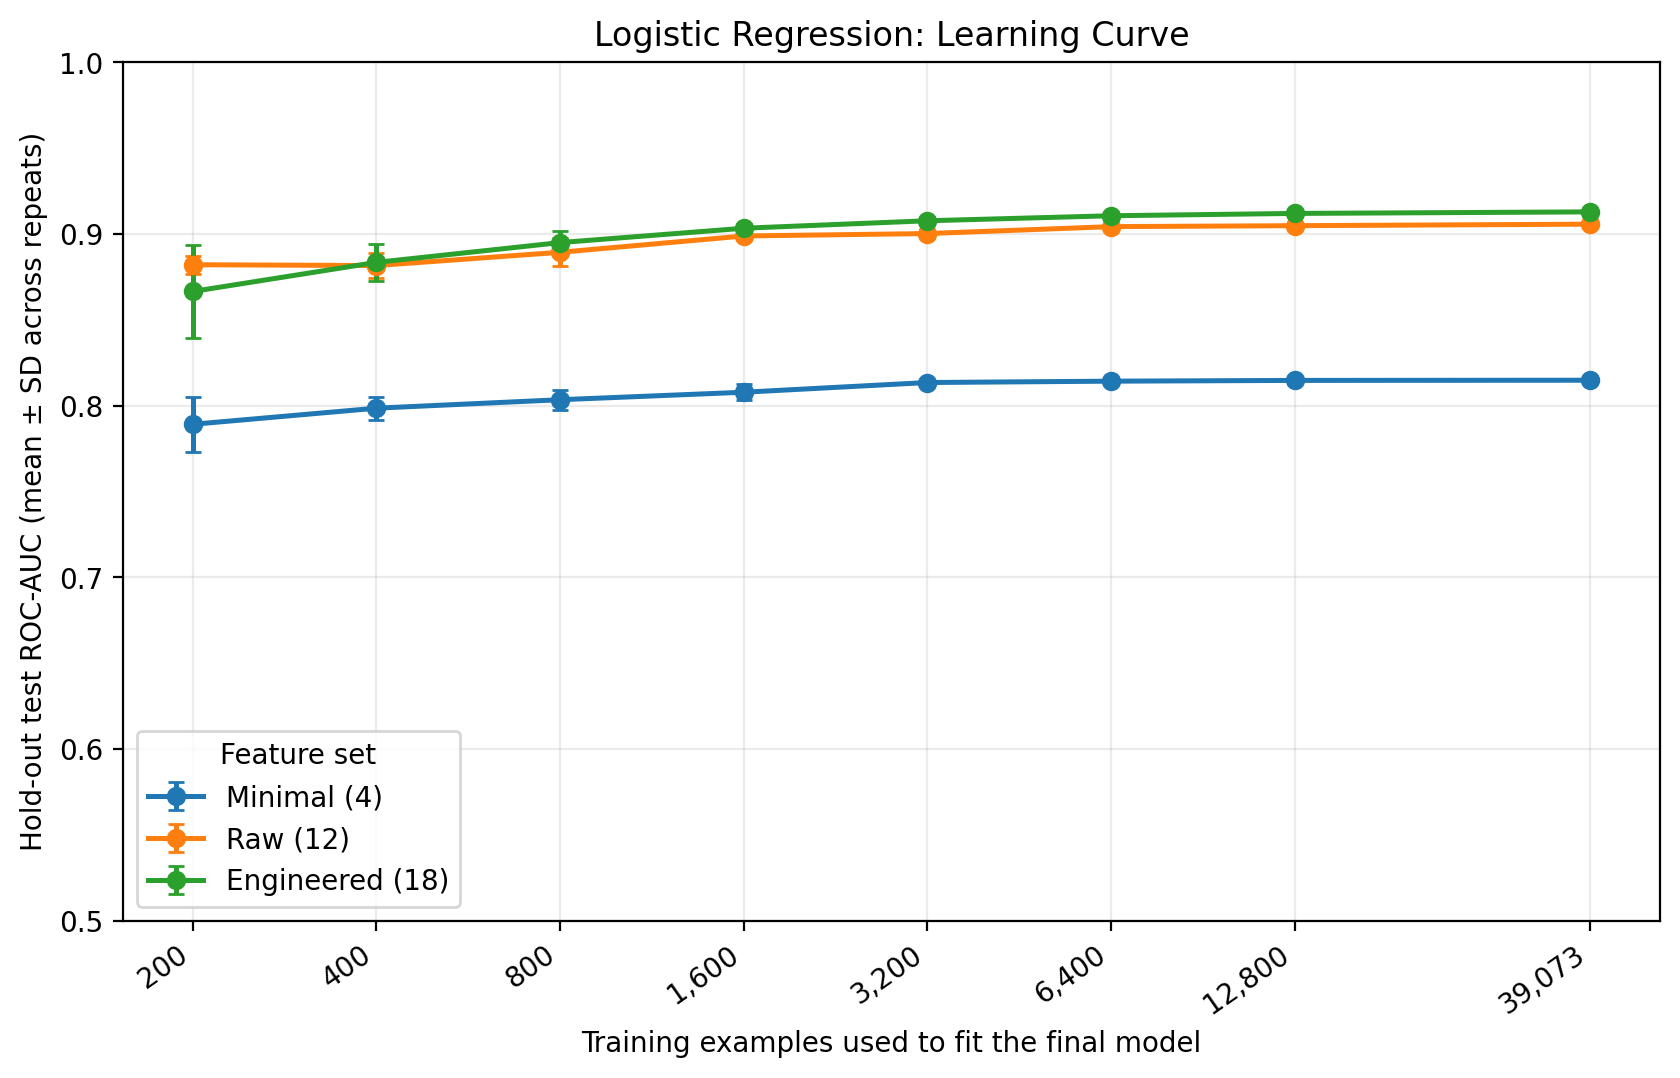

decision_tree_learning_curve.png


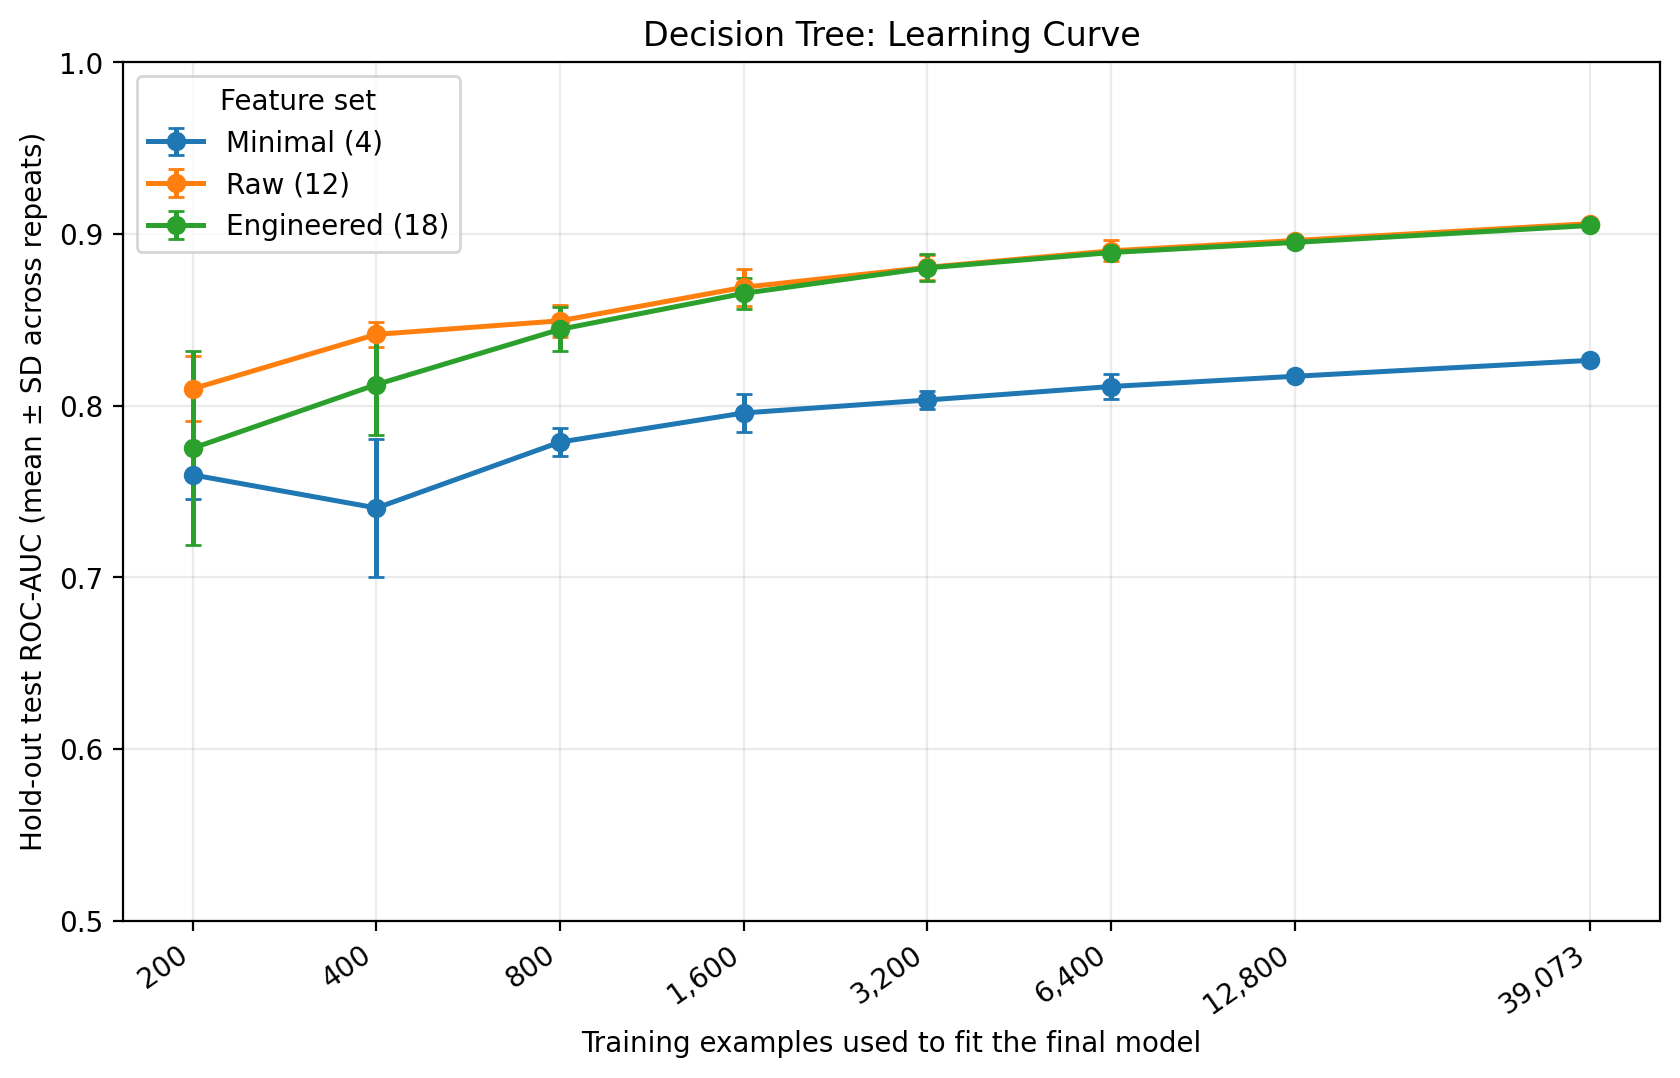

random_forest_learning_curve.png


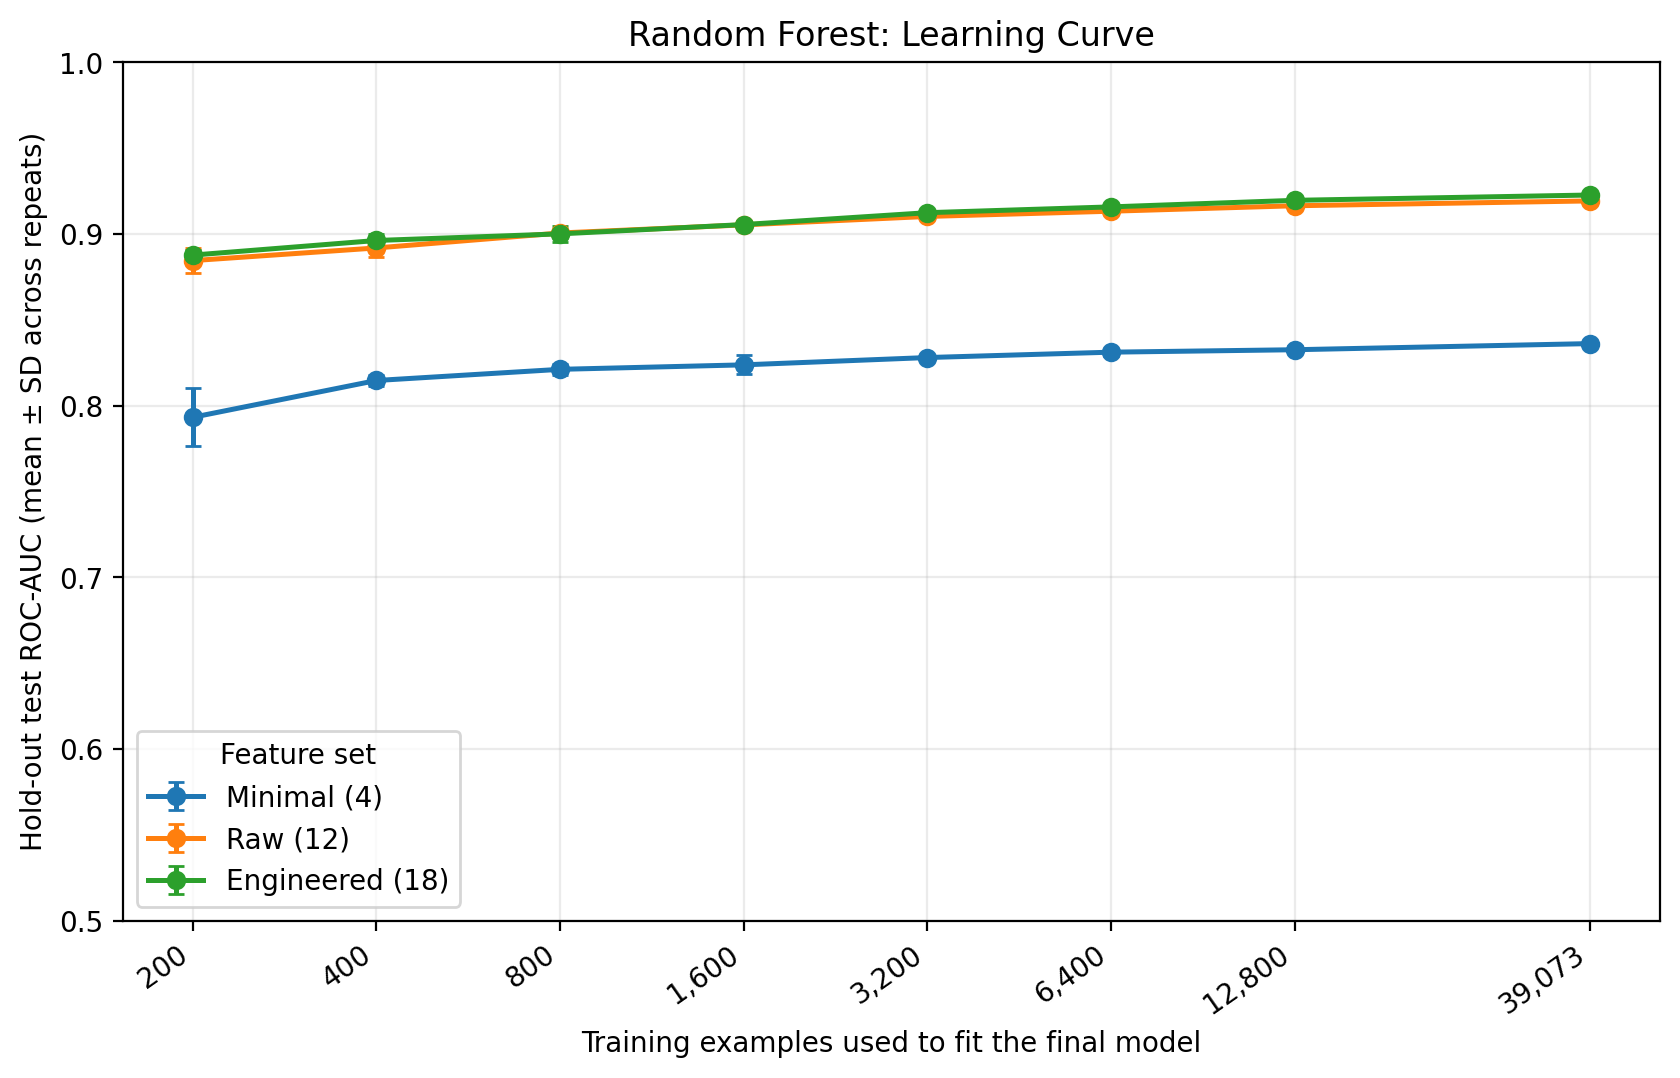

decision_tree_depth_validation.png


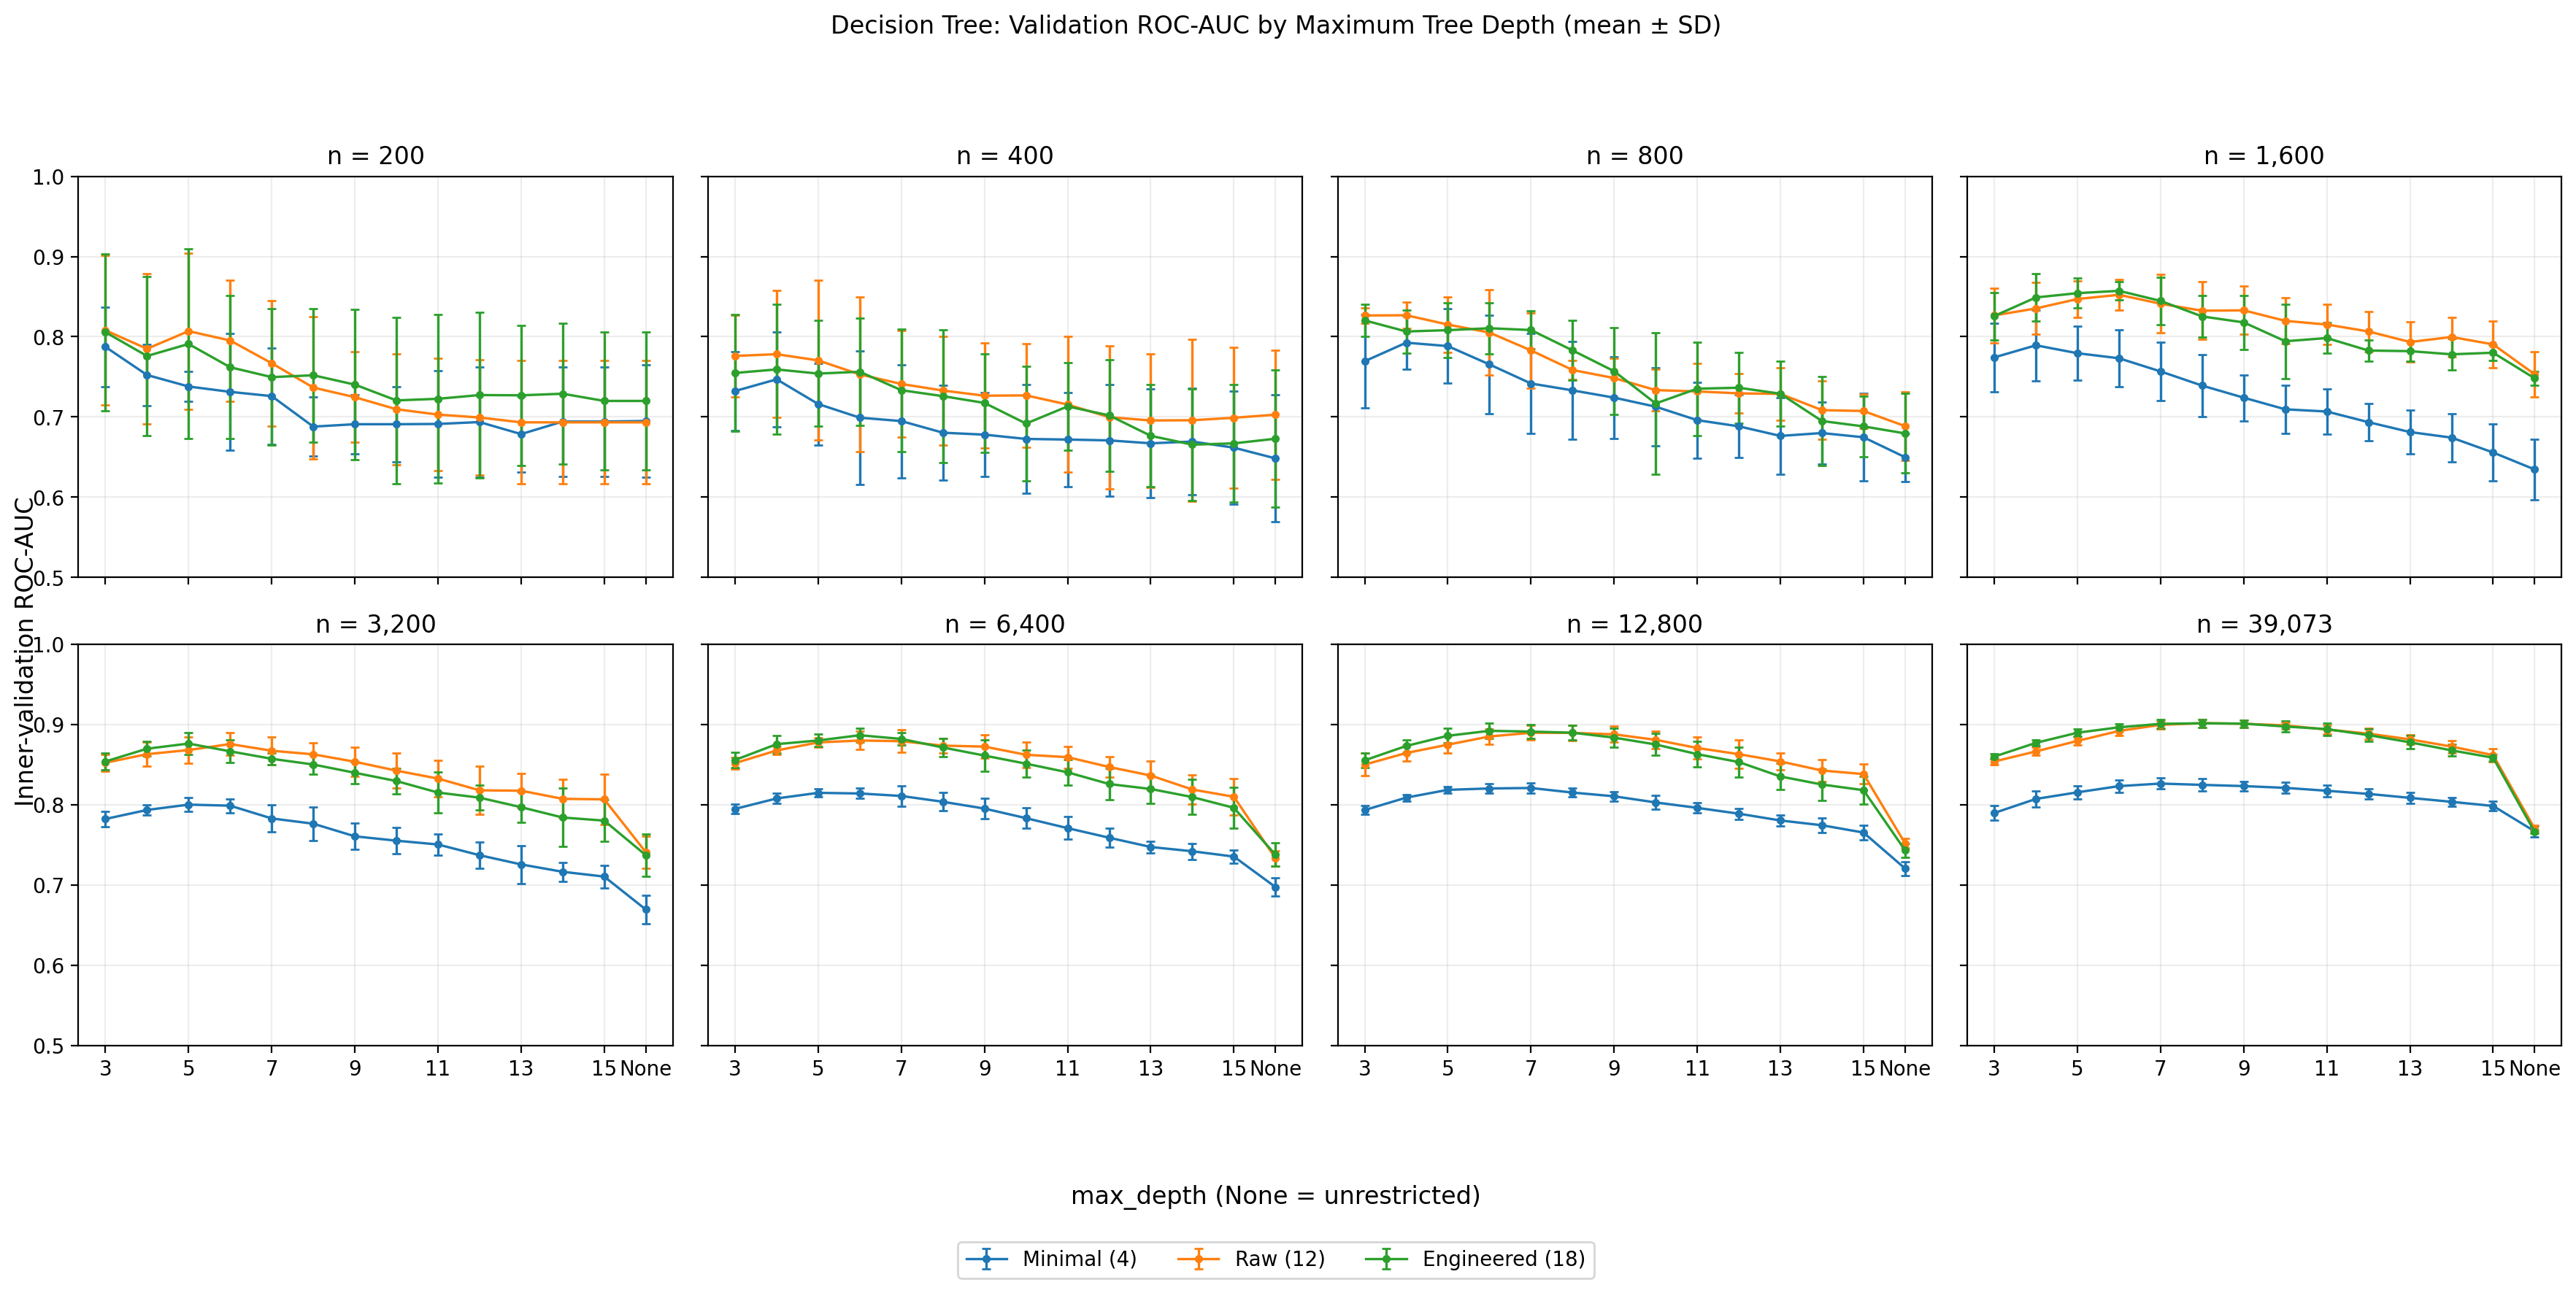

random_forest_depth_validation.png


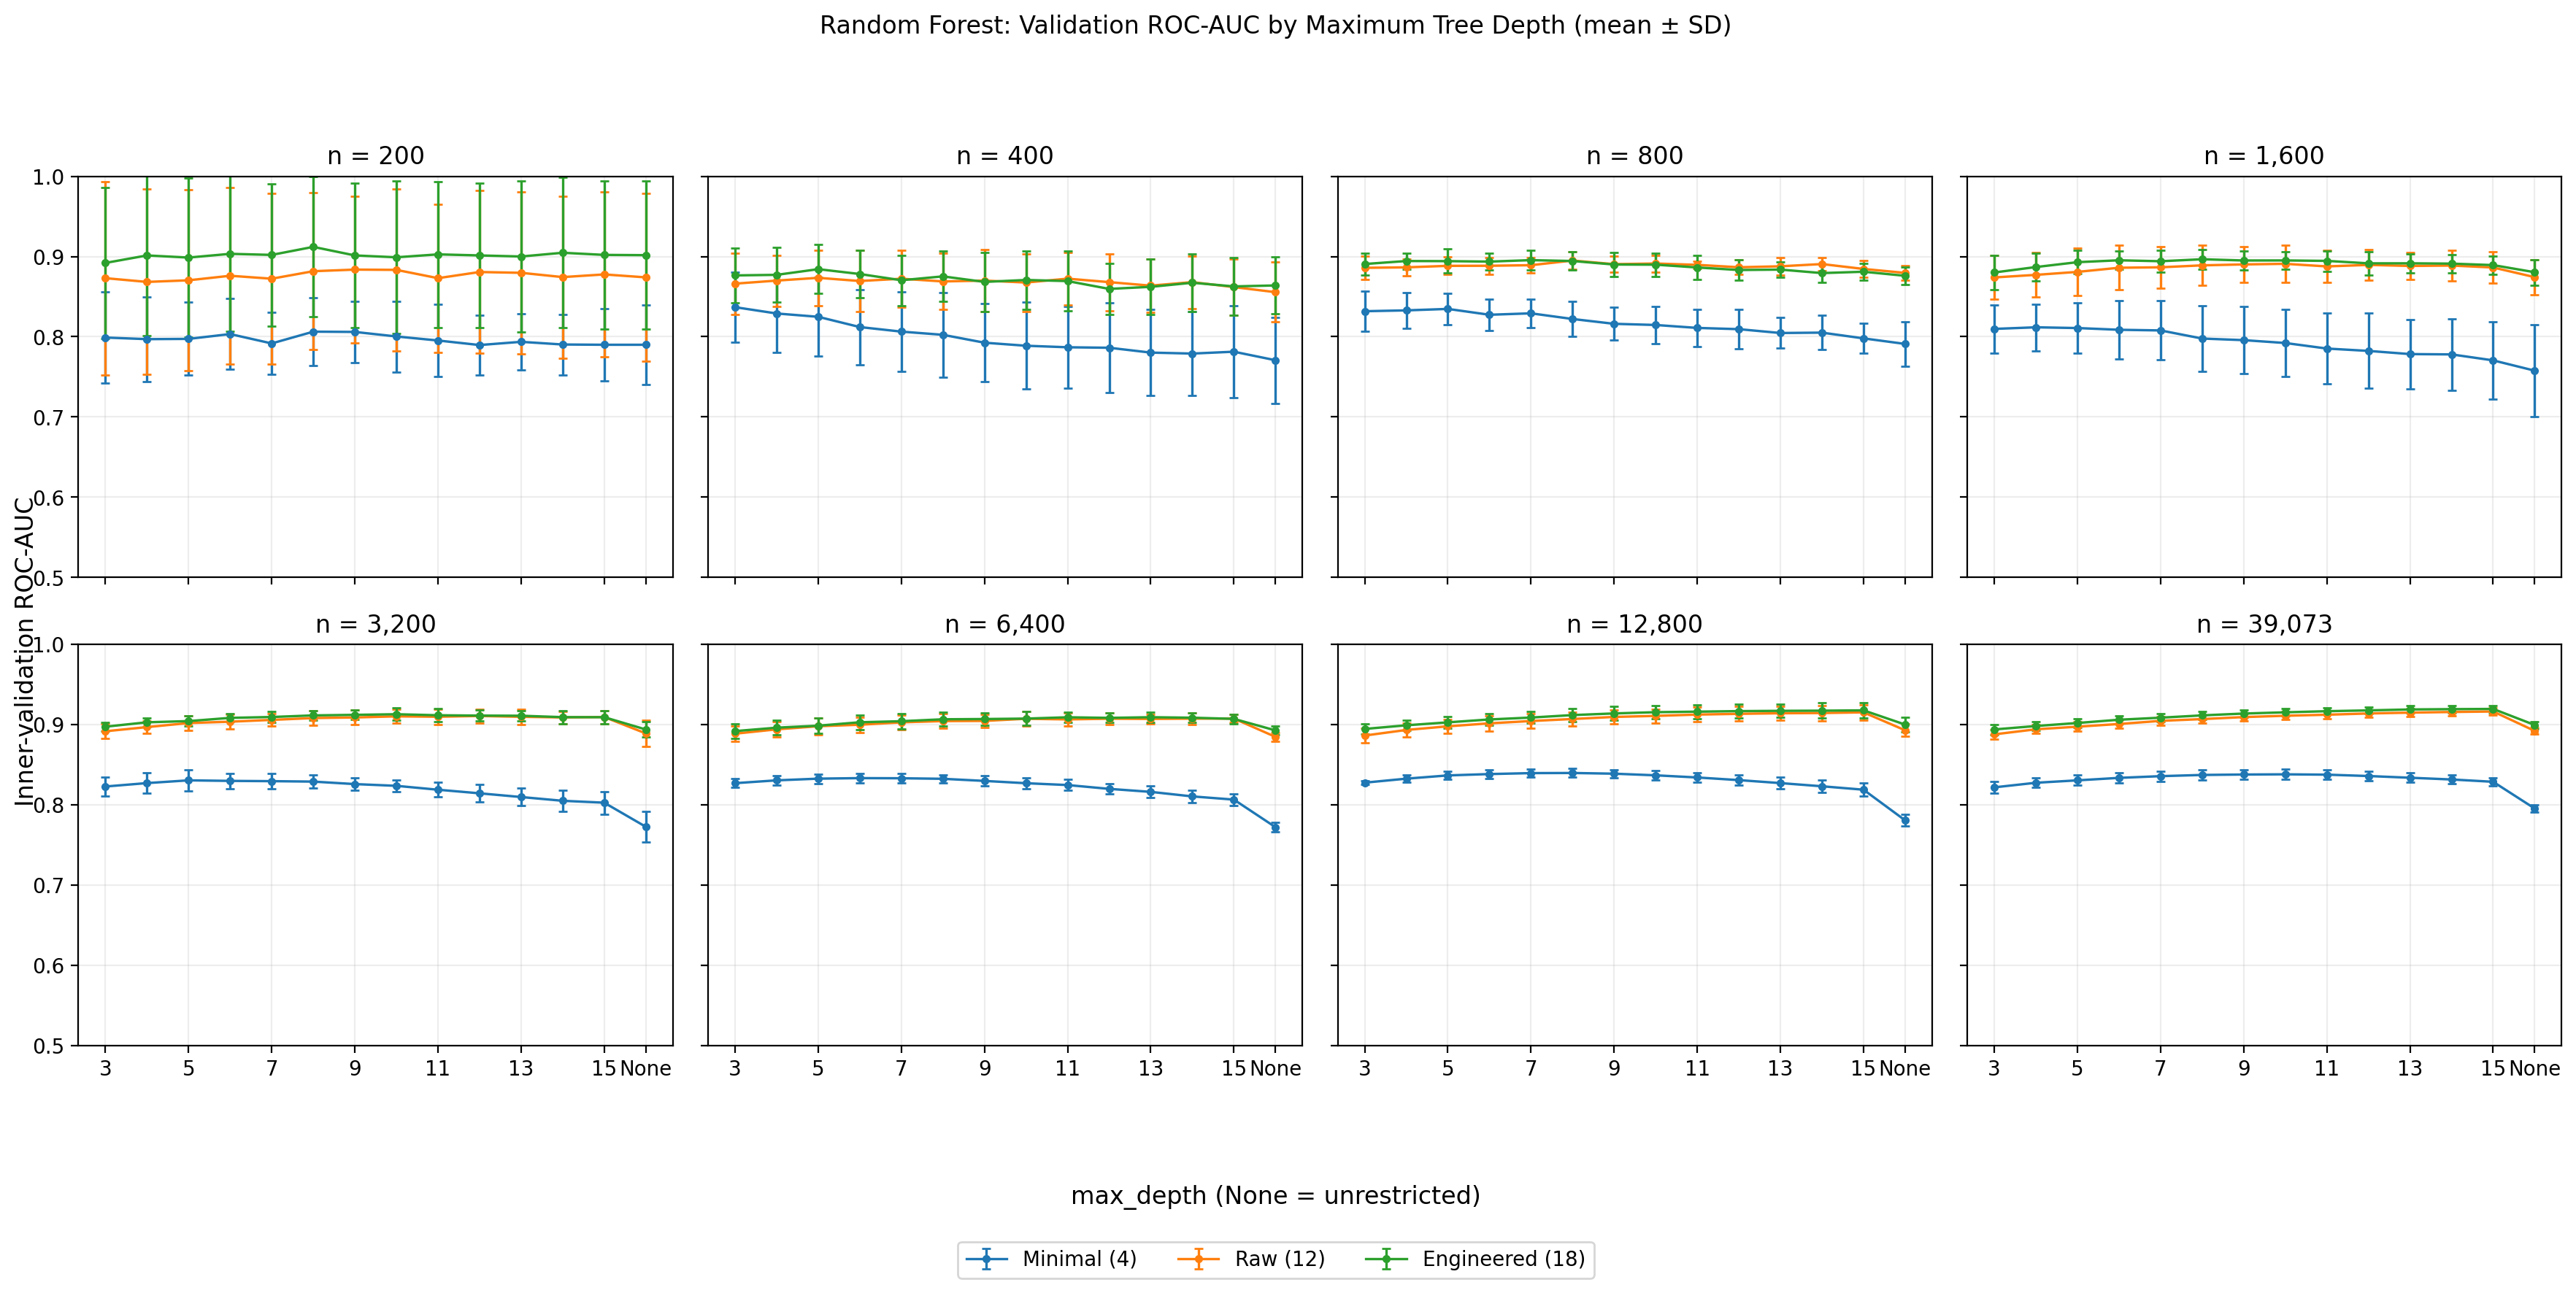

In [11]:
# Display the three learning curves and two validation-depth figures in the notebook.

from IPython.display import display, Image

for filename in [
    "logistic_regression_learning_curve.png",
    "decision_tree_learning_curve.png",
    "random_forest_learning_curve.png",
    "decision_tree_depth_validation.png",
    "random_forest_depth_validation.png",
]:
    image_path = final_output_dir / filename
    if image_path.exists():
        print(filename)
        display(Image(filename=str(image_path)))

In [12]:
# Optional: download a ZIP of the final in-Colab experiment outputs.
# The Drive folder remains the persistent copy.

import shutil
from google.colab import files

final_zip_path = shutil.make_archive(
    "/content/research_outputs_colab_final",
    "zip",
    root_dir=final_output_dir,
)
print("Created:", final_zip_path)
files.download(final_zip_path)

Created: /content/research_outputs_colab_final.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>